# code_145 · A pinned TabPFN checkpoint under whole-building assessment

**Book:** section 28.2. A self-contained reusable-model laboratory with generated records, explicit source assumptions and preserved provenance. Prerequisites: Python arrays/tables and Chapter 8's information contracts. Restart and run all cells. Task inputs and helpers are internal. Ordinary execution is offline and CPU-only after the explicit one-time public checkpoint acquisition in the asset guide; local weights are hash-verified, and missing assets fail with instructions. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_28_GUIDE.md), [run evidence](../CHAPTER_28_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_145).

Reference: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute to execute and 30–60 minutes to interpret. These scoped experiments expose task/data and fixed fitting controls rather than claim exhaustive estimator API coverage. Splits, fitted transformations, model selection and assessment declare their evidence boundaries locally. Synthetic cohort sizes and prevalences are constructed rather than population estimates. Task inputs are generated. Named pretrained weights, where used, require the explicitly documented one-time acquisition and immutable hash checks. These comparisons expose structural assumptions, information boundaries and transformation contracts without field-validity, causal or universal physical-model claims.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
import threadpoolctl
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
START=time.perf_counter();SEED=3545;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
import torch
from torch import nn
torch.set_num_threads(1);torch.set_default_dtype(torch.float32);torch.manual_seed(SEED);torch.use_deterministic_algorithms(True)
VERSIONS['torch']=torch.__version__
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0'}
CPU: Darwin arm64 seed: 3545


<a id="pinned-tabpfn-contract"></a>
 ## A family name does not identify the executed model
 Built with PriorLabs-TabPFN. This notebook executes TabPFN9.2.0 with the public v2 classifier checkpoint, not the library's newer default3.5weights. Read the [asset instructions and licence notices](../CHAPTER_28_ASSETS.md); run `python scripts/acquire_chapter28_models.py` explicitly once from the companion root. Ordinary notebook execution is offline and checks its local29,009,539-byte checkpoint SHA-256 against an immutable Hub revision. Missing weights cause an actionable failure, never a replacement predictor. Sixty generated buildings×10records split40source/10development/10final; twenty separate changed-mechanism buildings assess support shift. Five numeric fields include declared missing sensor values. Labelled source rows form TabPFN context; no pretrained parameters are optimized on this task. Native HistGradientBoosting controls receive the same rows and missingness, with their own declared candidate grid.


Native packages: {'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0', 'torch': '2.14.1', 'tabpfn': '9.2.0', 'huggingface-hub': '1.33.0'}


tabpfn/validation.py:234: UserWarning: Running on CPU with more than 200 samples may be slow.
Consider using a GPU or the tabpfn-client API: https://github.com/PriorLabs/tabpfn-client
  _validate_num_samples_for_cpu(


tabpfn/validation.py:234: UserWarning: Running on CPU with more than 200 samples may be slow.
Consider using a GPU or the tabpfn-client API: https://github.com/PriorLabs/tabpfn-client
  _validate_num_samples_for_cpu(


,family,candidate,development_Brier,labelled_source_records,ensemble_members
0,TabPFN v2,TabPFN v2 ensemble 1,0.167225,400,1
1,TabPFN v2,TabPFN v2 ensemble 4,0.171492,400,4
2,Native histogram booster,Histogram rate 0.05 leaves 7,0.178405,400,100
3,Native histogram booster,Histogram rate 0.05 leaves 15,0.180732,400,100
4,Native histogram booster,Histogram rate 0.1 leaves 7,0.185244,400,100
5,Native histogram booster,Histogram rate 0.1 leaves 15,0.184499,400,100


,family,selected_candidate,cohort,records,positive_records,Brier,log_loss,AUC
0,TabPFN v2,TabPFN v2 ensemble 1,Final buildings,100,36,0.182998,0.552342,0.787326
1,TabPFN v2,TabPFN v2 ensemble 1,Changed mechanism,200,33,0.272313,0.761461,0.437307
2,Native histogram booster,Histogram rate 0.05 leaves 7,Final buildings,100,36,0.202165,0.605295,0.741753
3,Native histogram booster,Histogram rate 0.05 leaves 7,Changed mechanism,200,33,0.313088,0.853824,0.464707


Selected: {'TabPFN v2': 'TabPFN v2 ensemble 1', 'Native histogram booster': 'Histogram rate 0.05 leaves 7'}


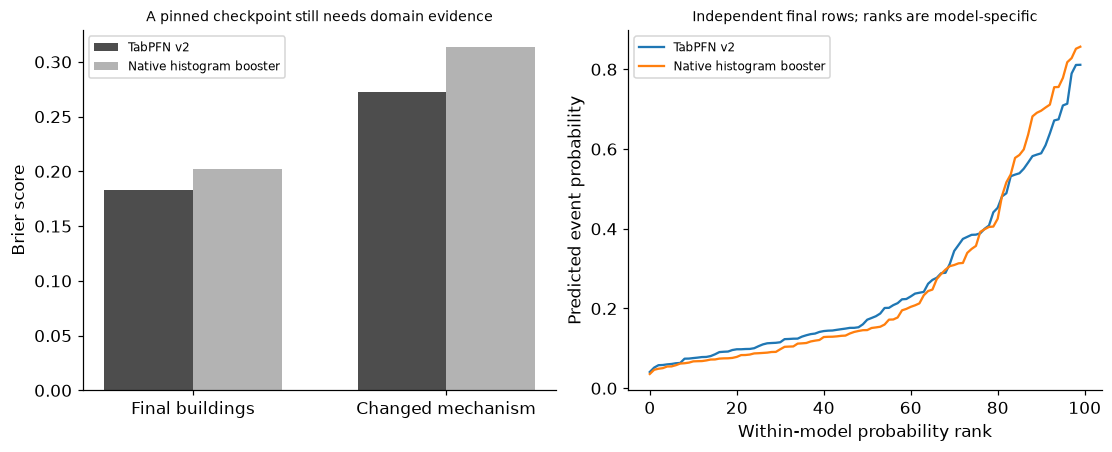

In [2]:
import os,hashlib,importlib.metadata as metadata
from pathlib import Path
os.environ['HF_HUB_OFFLINE']='1'
from tabpfn import TabPFNClassifier
import warnings,sys
# Preserve every warning, with package-relative locations instead of a local account path.
def render_warning(message,category,filename,lineno,file=None,line=None):
    parts=Path(filename).parts;location=str(Path(*parts[parts.index('site-packages')+1:])) if 'site-packages' in parts else Path(filename).name;(file or sys.stderr).write(warnings.formatwarning(message,category,location,lineno,line))
warnings.showwarning=render_warning
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import brier_score_loss,roc_auc_score,log_loss
VERSIONS['tabpfn']=metadata.version('tabpfn');VERSIONS['huggingface-hub']=metadata.version('huggingface-hub');print('Native packages:',VERSIONS)
candidates=[Path.cwd(),Path.cwd().parent,Path.cwd()/'examples'];ROOT=next(p for p in candidates if (p/'examples.json').is_file());revision='f851f2a3c941544733b712d8c0f96dfae9b28862';filename='tabpfn-v2-classifier-v2_default.ckpt';checkpoint=ROOT/'build/model-cache/models--Prior-Labs--TabPFN-v2-clf/snapshots'/revision/filename;expected_hash='cf8c519c01eaf1613ee91239006d57b1c806ff5f23ac1aeb1315ba1015210e49'
assert checkpoint.is_file(),'Missing pinned weights: from companion root run python scripts/acquire_chapter28_models.py; see CHAPTER_28_ASSETS.md'
data=checkpoint.read_bytes();assert len(data)==29009539 and hashlib.sha256(data).hexdigest()==expected_hash;del data
def cohort(buildings,changed=False):
    group=np.repeat(np.arange(buildings),10);latent=rng.normal(size=(buildings*10,5));latent[:,0]+=1.2*changed;latent[:,2]+=.7*changed;effect=rng.normal(0,.35,buildings)[group];score=-1+(-.8 if changed else .8)*latent[:,0]-.7*latent[:,1]+.6*latent[:,2]*latent[:,3]+.2*latent[:,4]+effect;prob=1/(1+np.exp(-score));label=rng.binomial(1,prob);observed=latent.copy();observed[rng.uniform(size=len(group))<.05,1]=np.nan;return group,observed,label
group,x,y=cohort(60);shift_group,shift_x,shift_y=cohort(20,True);source=group<40;dev=(group>=40)&(group<50);final=group>=50;rows=[];fitted={};best={}
for ensemble in [1,4]:
    learner=TabPFNClassifier(n_estimators=ensemble,model_path=checkpoint,device='cpu',inference_precision=torch.float32,n_preprocessing_jobs=1,random_state=SEED);learner.fit(x[source],y[source]);p=learner.predict_proba(x[dev])[:,1];score=float(brier_score_loss(y[dev],p));name=f'TabPFN v2 ensemble {ensemble}';rows.append({'family':'TabPFN v2','candidate':name,'development_Brier':score,'labelled_source_records':int(source.sum()),'ensemble_members':learner.n_estimators_});fitted[name]=learner
    if 'TabPFN v2' not in best or score<best['TabPFN v2'][0]:best['TabPFN v2']=(score,name)
for rate in [.05,.1]:
    for leaves in [7,15]:
        learner=HistGradientBoostingClassifier(max_iter=100,learning_rate=rate,max_leaf_nodes=leaves,min_samples_leaf=15,l2_regularization=1,early_stopping=False,random_state=SEED).fit(x[source],y[source]);p=learner.predict_proba(x[dev])[:,1];score=float(brier_score_loss(y[dev],p));name=f'Histogram rate {rate:g} leaves {leaves}';rows.append({'family':'Native histogram booster','candidate':name,'development_Brier':score,'labelled_source_records':int(source.sum()),'ensemble_members':100});fitted[name]=learner
        if 'Native histogram booster' not in best or score<best['Native histogram booster'][0]:best['Native histogram booster']=(score,name)
def weight_hash(learner):return hashlib.sha256(b''.join(p.detach().cpu().numpy().tobytes() for module in learner.models_ for p in module.parameters())).hexdigest()
selected=fitted[best['TabPFN v2'][1]];before=weight_hash(selected);repeat1=selected.predict_proba(x[final]);repeat2=selected.predict_proba(x[final]);np.testing.assert_allclose(repeat1,repeat2,rtol=0,atol=1e-7);assert weight_hash(selected)==before
assessments=[];probabilities={}
for family,(_,name) in best.items():
    learner=fitted[name]
    for cohort_name,xx,yy in [('Final buildings',x[final],y[final]),('Changed mechanism',shift_x,shift_y)]:
        p=learner.predict_proba(xx)[:,1];assert np.all((p>=0)&(p<=1));probabilities[(family,cohort_name)]=p;assessments.append({'family':family,'selected_candidate':name,'cohort':cohort_name,'records':len(yy),'positive_records':int(yy.sum()),'Brier':float(brier_score_loss(yy,p)),'log_loss':float(log_loss(yy,np.column_stack([1-p,p]),labels=[0,1])),'AUC':float(roc_auc_score(yy,p))})
source_rate=float(y[source].mean());baseline=[{'cohort':name,'Brier':float(np.mean((yy-source_rate)**2))} for name,yy in [('Final buildings',y[final]),('Changed mechanism',shift_y)]]
RESULTS.update(building_counts=[40,10,10,20],record_counts=[400,100,100,200],checkpoint_repository='Prior-Labs/TabPFN-v2-clf',checkpoint_revision=revision,checkpoint_filename=filename,checkpoint_sha256=expected_hash,checkpoint_bytes=29009539,candidate_development=rows,selected_candidates={family:name for family,(_,name) in best.items()},assessments=assessments,source_prevalence=source_rate,source_prevalence_baseline=baseline,source_missing_sensor_records=int(np.isnan(x[source,1]).sum()),pretrained_parameters=sum(p.numel() for module in selected.models_ for p in module.parameters()),native_pretrained_weights_unchanged_by_prediction=weight_hash(selected)==before);display(pd.DataFrame(rows));display(pd.DataFrame(assessments));print('Selected:',RESULTS['selected_candidates'])
fig,axes=plt.subplots(1,2,figsize=(10,4));xx=np.arange(2)
for j,family in enumerate(best):values=[r['Brier'] for r in assessments if r['family']==family];axes[0].bar(xx+(j-.5)*.35,values,.35,color=['.3','.7'][j],label=family)
axes[0].set(xticks=xx,xticklabels=['Final buildings','Changed mechanism'],ylabel='Brier score',title='A pinned checkpoint still needs domain evidence');axes[0].legend(fontsize=8)
for family in best:p=probabilities[(family,'Final buildings')];order=np.argsort(p);axes[1].plot(np.arange(len(p)),p[order],label=family)
axes[1].set(xlabel='Within-model probability rank',ylabel='Predicted event probability',title='Independent final rows; ranks are model-specific');axes[1].legend(fontsize=8);plt.show()


<a id="checkpoint-context-and-evidence"></a>
 ## Native fitting controls do not erase unequal upstream budgets
 Two ensemble sizes select the native TabPFN recipe; four fixed learning-rate/leaf-count candidates select the booster using the same100development records. These are declared candidate budgets, not equal lifetime computation: the public pretrained checkpoint has a substantial upstream training history absent from the fitted tree. Final100records and200changed-mechanism records never select a setting. Missing values remain available to each native input path rather than receiving an assumed universal imputer. TabPFN's wrapper fits task-specific preprocessing/context state; hashes test unchanged learned network parameters across actual predictions, not immutability of every fitted wrapper attribute. Population probabilities and AUC answer different questions. Source resampling can estimate entity uncertainty in a larger analysis, but this single generated split does not claim a precise universal model ordering or fresh evidence about the checkpoint's upstream sources.


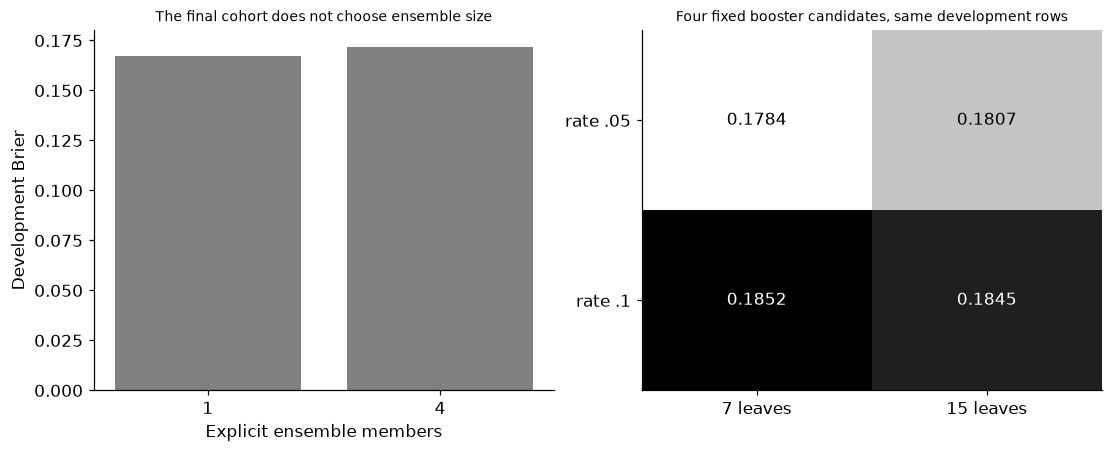

In [3]:
fig,axes=plt.subplots(1,2,figsize=(10,4));names=list(best);source_rows=[r for r in rows if r['family']=='TabPFN v2'];axes[0].bar([str(r['ensemble_members']) for r in source_rows],[r['development_Brier'] for r in source_rows],color='.5');axes[0].set(xlabel='Explicit ensemble members',ylabel='Development Brier',title='The final cohort does not choose ensemble size')
tree_rows=[r for r in rows if r['family']=='Native histogram booster'];matrix=np.array([r['development_Brier'] for r in tree_rows]).reshape(2,2);axes[1].imshow(matrix,cmap='Greys',aspect='auto')
for j in range(2):
    for k in range(2):axes[1].text(k,j,f'{matrix[j,k]:.4f}',ha='center',va='center',color='white' if matrix[j,k]>(matrix.max()+matrix.min())/2 else 'black')
axes[1].set(xticks=[0,1],xticklabels=['7 leaves','15 leaves'],yticks=[0,1],yticklabels=['rate .05','rate .1'],title='Four fixed booster candidates, same development rows');plt.show()
assert len(assessments)==4 and all(np.isfinite(row['Brier']) for row in assessments)


In [4]:
summary={'example_id':'code_145','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['actual pinned TabPFN v2 CPU inference', 'explicit offline checkpoint hash verification', 'whole-building development selection versus final assessment', 'native missing-value handling and fixed tree controls', 'unchanged pretrained weights with labelled context'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
if 'resource_profile' in globals():summary['resource_observations']=resource_profile
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["actual pinned TabPFN v2 CPU inference", "explicit offline checkpoint hash verification", "whole-building development selection versus final assessment", "native missing-value handling and fixed tree controls", "unchanged pretrained weights with labelled context"], "elapsed_seconds": 3.653, "example_id": "code_145", "hardware": "Darwin arm64 CPU", "results": {"assessments": [{"AUC": 0.7873263888888888, "Brier": 0.18299755454063416, "cohort": "Final buildings", "family": "TabPFN v2", "log_loss": 0.5523422360420227, "positive_records": 36, "records": 100, "selected_candidate": "TabPFN v2 ensemble 1"}, {"AUC": 0.4373072037742697, "Brier": 0.2723129987716675, "cohort": "Changed mechanism", "family": "TabPFN v2", "log_loss": 0.7614613175392151, "positive_records": 33, "records": 200, "selected_candidate": "TabPFN v2 ensemble 1"}, {"AUC": 0.7417534722222222, "Brier": 0.20216491229892009, "cohort": "Final buildings", "family": "Native histogra